In [1]:
from pathlib import Path
import pandas as pd

CSV_PATH = Path("historique_merged.csv")

with CSV_PATH.open("rb") as f:
    nb_lignes = sum(1 for _ in f)
print(f"{nb_lignes:,} lignes dans le fichier".replace(",", " "))

3 757 220 lignes dans le fichier


In [2]:
df = pd.read_csv(CSV_PATH, header=None)
print(df.shape)
df.head()

(3757220, 8)


,0,1,2,3,4,5,6,7
0,2026-10-16T11:52Z,10003,17,1,1,Hauteville - Bonne Nouvelle,"48.87077,2.34965",True
1,2026-10-16T11:52Z,10004,48,1,4,Metz - Faubourg Saint-Denis,"48.87089,2.35352",True
2,2026-10-16T11:52Z,10005,17,0,9,Petites Ecuries - Faubourg Poissonnière,"48.87397,2.34839",True
3,2026-10-16T11:52Z,10006,28,3,20,Petites Ecuries - Faubourg Saint-Denis,"48.87287,2.35422",True
4,2026-10-16T11:52Z,10008,18,4,2,Cité Riverin - Château d'Eau,"48.87070,2.35874",True


In [ ]:
# Renommer les colonnes et convertir les types de données
COLONNES = [
    "horodatage", "station_code", "capacity", "velo_meca", "velo_elec",
    "station_name", "coordonnees", "operative",
]

df = pd.read_csv(CSV_PATH, header=None, names=COLONNES)
df["horodatage"] = pd.to_datetime(df["horodatage"], utc=True)
df[["latitude", "longitude"]] = df["coordonnees"].str.split(",", expand=True).astype(float)
df = df.drop(columns="coordonnees")

In [ ]:
# Fusion des colonnes "velo_meca" et #velo_elec" pour créer une nouvelle colonne "available" 
df["available"] = df["velo_meca"] + df["velo_elec"]

In [5]:
# Ecarter les stations en dehors de Paris 
dans_paris = df["latitude"].between(48.815, 48.902) & df["longitude"].between(2.224, 2.470)
df = df[dans_paris].copy()

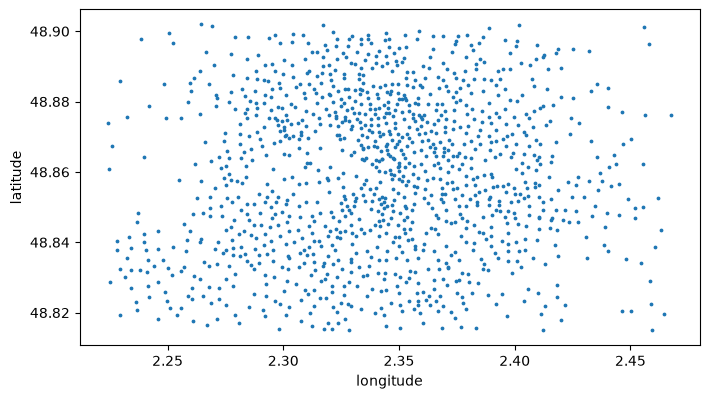

In [8]:
# Voir ce que ça donne sur une carte 
import numpy as np

stations = df.drop_duplicates("station_code")
ax = stations.plot.scatter(x="longitude", y="latitude", s=3, figsize=(8, 8))
ax.set_aspect(1 / np.cos(np.radians(48.86)))

In [6]:
# Suppressions des stations à capacité nulle (0)
df = df[df["capacity"] > 0].copy()

In [9]:
# Vérification 
print(df["capacity"].min()) 
print((df["capacity"] == 0).sum())

11
0


In [10]:
# Je vais chercher à isoler les cas problématiques, c-à-d les stations où la capacité est inférieur aux nombres de vélos dispo
anomalies = df[df["available"] > df["capacity"]].copy()
anomalies["exces"] = anomalies["available"] - anomalies["capacity"]

print(f"{len(anomalies):,} lignes sur {len(df):,} ({len(anomalies) / len(df):.2%})")
print(f"{anomalies['station_code'].nunique()} stations sur {df['station_code'].nunique()}")
anomalies["exces"].describe()

7,463 lignes sur 3,004,147 (0.25%)
17 stations sur 1215


count    7463.000000
mean        9.544687
std         8.191153
min         1.000000
25%         3.000000
50%         7.000000
75%        14.000000
max        40.000000
Name: exces, dtype: float64

In [11]:
# Trouver les cas les plus extrêmes 
anomalies.sort_values("exces", ascending=False).head(10)[
    ["horodatage", "station_code", "station_name", "capacity", "velo_meca", "velo_elec", "operative", "exces"]
]

,horodatage,station_code,station_name,capacity,velo_meca,velo_elec,operative,exces
3251652,2026-10-24 14:30:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3245576,2026-10-24 14:10:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,46,36,True,40
3244057,2026-10-24 14:05:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,46,36,True,40
3247095,2026-10-24 14:15:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,46,36,True,40
3256209,2026-10-24 14:45:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3257728,2026-10-24 14:50:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3254690,2026-10-24 14:40:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3253171,2026-10-24 14:35:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3248614,2026-10-24 14:20:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,46,36,True,40
3250133,2026-10-24 14:25:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,46,36,True,40
